In [1]:
"""
WESAD Binary Stress Detection - Notebook 2: Preprocessing & Windowing
======================================================================
STRICT COMPLIANCE: All fixed values must be used exactly as specified.
"""

# ============================================================================
# FIXED CONFIGURATION - DO NOT MODIFY
# ============================================================================

PREPROCESS_CONFIG = {
    # Sampling & Windowing (FIXED)
    'target_sampling_rate': 4,  # FIXED: 4 Hz after resampling
    'window_length_seconds': 60,  # FIXED: 60 seconds
    'samples_per_window': 240,  # FIXED: 240 timesteps (60s * 4Hz)
    'window_overlap': 0.5,  # FIXED: 50% overlap
    
    # Normalization (FIXED)
    'normalization_method': 'z_score',  # FIXED
    'normalization_scope': 'per_subject_per_channel',  # FIXED
    'normalize_after_windowing': True,  # FIXED
    
    # Data Splitting (FIXED)
    'split_type': 'subject_independent',  # FIXED
    'split_strategy': 'LOSO',  # FIXED: Leave-One-Subject-Out OR explicit subject IDs
}

In [2]:
# ============================================================================
# IMPORTS
# ============================================================================

import numpy as np
import pickle
from pathlib import Path
from scipy import signal as scipy_signal
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

In [3]:
# ============================================================================
# LOAD DATA FROM NOTEBOOK 1
# ============================================================================

def load_raw_data(input_file='processed_data/raw_loaded_data.pkl'):
    """Load data saved from Notebook 1."""
    with open(input_file, 'rb') as f:
        saved_data = pickle.load(f)
    
    print(f"Loaded {len(saved_data['data'])} subjects")
    return saved_data['data'], saved_data['config']

In [4]:
# ============================================================================
# SIGNAL PREPROCESSING FUNCTIONS
# ============================================================================

def bandpass_filter(data, lowcut, highcut, fs, order=4):
    """Apply bandpass filter to signal."""
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = scipy_signal.butter(order, [low, high], btype='band')
    filtered_data = scipy_signal.filtfilt(b, a, data)
    return filtered_data

def smooth_signal(data, window_size=5):
    """Apply moving average smoothing."""
    kernel = np.ones(window_size) / window_size
    smoothed_data = np.convolve(data, kernel, mode='same')
    return smoothed_data

def preprocess_ecg(ecg_signal, fs=700):
    """
    Preprocess ECG signal.
    - Apply bandpass filter (0.5-50 Hz)
    """
    # Bandpass filter
    filtered_ecg = bandpass_filter(ecg_signal, lowcut=0.5, highcut=50, fs=fs)
    return filtered_ecg

def preprocess_eda(eda_signal, fs=700):
    """
    Preprocess EDA signal.
    - Apply smoothing
    """
    # Smoothing
    smoothed_eda = smooth_signal(eda_signal, window_size=int(fs * 0.1))  # 100ms window
    return smoothed_eda

def preprocess_emg(emg_signal, fs):
    """
    Preprocess EMG signal.
    - Apply bandpass filter (20-450 Hz) for noise reduction
    """
    # Bandpass filter
    filtered_emg = bandpass_filter(
        emg_signal,
        lowcut=20,
        highcut=250,   # FIXED
        fs=fs,
        order=4
    )
    return filtered_emg


def preprocess_respiration(resp_signal):
    """
    Preprocess Respiration signal.
    - Minimal processing (already clean in WESAD)
    """
    return resp_signal

def preprocess_temperature(temp_signal):
    """
    Preprocess Temperature signal.
    - Minimal processing
    """
    return temp_signal

def apply_signal_specific_preprocessing(signals, fs=700):
    """
    Apply signal-specific preprocessing to all signals.
    
    Args:
        signals: Dictionary of signal arrays
        fs: Original sampling rate
        
    Returns:
        Dictionary of preprocessed signals
    """
    preprocessed = {}
    
    preprocessed['ECG'] = preprocess_ecg(signals['ECG'], fs)
    preprocessed['EDA'] = preprocess_eda(signals['EDA'], fs)
    preprocessed['EMG'] = preprocess_emg(signals['EMG'], fs)
    preprocessed['Respiration'] = preprocess_respiration(signals['Respiration'])
    preprocessed['Temperature'] = preprocess_temperature(signals['Temperature'])
    
    return preprocessed

In [5]:
# ============================================================================
# RESAMPLING FUNCTION
# ============================================================================

def resample_signal(signal_data, original_fs, target_fs):
    """
    Resample signal from original sampling rate to target sampling rate.
    FIXED: Target sampling rate = 4 Hz
    
    Args:
        signal_data: Input signal array
        original_fs: Original sampling rate (700 Hz for WESAD chest)
        target_fs: Target sampling rate (FIXED: 4 Hz)
        
    Returns:
        Resampled signal array
    """
    original_length = len(signal_data)
    original_time = np.arange(original_length) / original_fs
    
    target_length = int(original_length * target_fs / original_fs)
    target_time = np.arange(target_length) / target_fs
    
    # Interpolate
    interpolator = interp1d(original_time, signal_data, kind='linear', 
                           fill_value='extrapolate', bounds_error=False)
    resampled_signal = interpolator(target_time)
    
    return resampled_signal

def resample_all_signals(signals, labels, original_fs, target_fs=4):
    """
    Resample all signals and labels to target sampling rate.
    FIXED: target_fs = 4 Hz
    """
    resampled_signals = {}
    
    # Resample each signal
    for signal_name, signal_data in signals.items():
        resampled_signals[signal_name] = resample_signal(signal_data, original_fs, target_fs)
    
    # Resample labels (use nearest neighbor)
    resampled_labels = resample_signal(labels.astype(float), original_fs, target_fs)
    resampled_labels = np.round(resampled_labels).astype(np.int32)
    
    return resampled_signals, resampled_labels

In [6]:
# ============================================================================
# WINDOWING FUNCTION
# ============================================================================

def create_windows(signals, labels, window_length=240, overlap=0.5):
    """
    Segment signals into fixed-length windows with overlap.
    
    FIXED PARAMETERS:
    - window_length: 240 samples (60 seconds * 4 Hz)
    - overlap: 0.5 (50%)
    
    Window labeling: Majority vote
    
    Args:
        signals: Dictionary of resampled signal arrays
        labels: Resampled label array
        window_length: FIXED: 240 samples
        overlap: FIXED: 0.5 (50%)
        
    Returns:
        windowed_signals: Dictionary of windowed signals (num_windows, window_length)
        window_labels: Array of window labels
    """
    signal_length = len(labels)
    step_size = int(window_length * (1 - overlap))
    
    # Calculate number of windows
    num_windows = (signal_length - window_length) // step_size + 1
    
    # Initialize storage
    windowed_signals = {name: [] for name in signals.keys()}
    window_labels = []
    
    for i in range(num_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_length
        
        if end_idx > signal_length:
            break
        
        # Extract window labels
        window_label_segment = labels[start_idx:end_idx]
        
        # Skip windows with undefined labels
        if np.any(window_label_segment == -1):
            continue
        
        # Majority vote for window label
        unique, counts = np.unique(window_label_segment, return_counts=True)
        majority_label = unique[np.argmax(counts)]
        
        # Extract signal windows
        for signal_name, signal_data in signals.items():
            windowed_signals[signal_name].append(signal_data[start_idx:end_idx])
        
        window_labels.append(majority_label)
    
    # Convert to numpy arrays
    for signal_name in windowed_signals.keys():
        windowed_signals[signal_name] = np.array(windowed_signals[signal_name])
    
    window_labels = np.array(window_labels)
    
    return windowed_signals, window_labels

In [7]:
# ============================================================================
# NORMALIZATION FUNCTION
# ============================================================================

def apply_zscore_normalization(windowed_signals):
    """
    Apply z-score normalization per channel.
    FIXED: Per subject, per channel, after windowing
    
    Args:
        windowed_signals: Dictionary of windowed signals (num_windows, window_length)
        
    Returns:
        Normalized windowed signals
    """
    normalized_signals = {}
    
    for signal_name, signal_windows in windowed_signals.items():
        # Compute mean and std across all windows for this subject and channel
        # Shape: (num_windows, window_length)
        
        # Flatten to compute statistics
        flattened = signal_windows.flatten()
        mean = np.mean(flattened)
        std = np.std(flattened)
        
        # Avoid division by zero
        if std < 1e-8:
            std = 1.0
        
        # Normalize
        normalized_signals[signal_name] = (signal_windows - mean) / std
    
    return normalized_signals

In [8]:
# ============================================================================
# FULL PREPROCESSING PIPELINE
# ============================================================================

def preprocess_subject(subject_id, subject_data):
    """
    Complete preprocessing pipeline for a single subject.
    
    Steps:
    1. Signal-specific preprocessing (filtering, smoothing)
    2. Resampling to 4 Hz (FIXED)
    3. Windowing (60s windows, 50% overlap) (FIXED)
    4. Z-score normalization per channel (FIXED)
    
    Returns:
        Dictionary containing windowed and normalized signals with labels
    """
    print(f"Processing {subject_id}...", end=' ')
    
    signals = subject_data['signals']
    labels = subject_data['labels']
    original_fs = subject_data['original_sampling_rate']
    
    # Step 1: Signal-specific preprocessing
    preprocessed_signals = apply_signal_specific_preprocessing(signals, original_fs)
    
    # Step 2: Resample to 4 Hz (FIXED)
    resampled_signals, resampled_labels = resample_all_signals(
        preprocessed_signals, labels, original_fs, 
        target_fs=PREPROCESS_CONFIG['target_sampling_rate']
    )
    
    # Step 3: Windowing (FIXED: 240 samples, 50% overlap)
    windowed_signals, window_labels = create_windows(
        resampled_signals, resampled_labels,
        window_length=PREPROCESS_CONFIG['samples_per_window'],
        overlap=PREPROCESS_CONFIG['window_overlap']
    )
    
    # Step 4: Z-score normalization (FIXED: per subject, per channel, after windowing)
    normalized_signals = apply_zscore_normalization(windowed_signals)
    
    num_windows = len(window_labels)
    print(f"✓ ({num_windows} windows)")
    
    return {
        'signals': normalized_signals,
        'labels': window_labels,
        'subject_id': subject_id,
        'num_windows': num_windows
    }

def preprocess_all_subjects(all_data):
    """
    Preprocess all subjects.
    
    Returns:
        Dictionary of preprocessed subject data
    """
    preprocessed_data = {}
    
    for subject_id, subject_data in all_data.items():
        preprocessed_data[subject_id] = preprocess_subject(subject_id, subject_data)
    
    return preprocessed_data

In [9]:
# ============================================================================
# DATA INSPECTION
# ============================================================================

def inspect_preprocessed_data(preprocessed_data):
    """Display statistics about preprocessed data."""
    print("\n" + "="*70)
    print("PREPROCESSED DATA SUMMARY")
    print("="*70)
    
    total_windows = 0
    total_stress = 0
    total_non_stress = 0
    
    print("\nPer-Subject Statistics:")
    print(f"{'Subject':<10} {'Windows':<10} {'Stress':<10} {'Non-Stress':<10} {'Balance':<10}")
    print("-" * 70)
    
    for subject_id, data in preprocessed_data.items():
        num_windows = data['num_windows']
        labels = data['labels']
        
        stress_count = np.sum(labels == 1)
        non_stress_count = np.sum(labels == 0)
        balance = stress_count / num_windows * 100 if num_windows > 0 else 0
        
        print(f"{subject_id:<10} {num_windows:<10} {stress_count:<10} {non_stress_count:<10} {balance:<10.1f}%")
        
        total_windows += num_windows
        total_stress += stress_count
        total_non_stress += non_stress_count
    
    print("-" * 70)
    print(f"{'Total':<10} {total_windows:<10} {total_stress:<10} {total_non_stress:<10} {total_stress/total_windows*100:<10.1f}%")
    
    print("\nSignal Shapes (example from first subject):")
    first_subject = list(preprocessed_data.keys())[0]
    signals = preprocessed_data[first_subject]['signals']
    for signal_name, signal_data in signals.items():
        print(f"  {signal_name:<15}: {signal_data.shape}")

def visualize_preprocessed_window(preprocessed_data):
    """Visualize a sample preprocessed window."""
    first_subject = list(preprocessed_data.keys())[0]
    signals = preprocessed_data[first_subject]['signals']
    labels = preprocessed_data[first_subject]['labels']
    
    # Get first window
    window_idx = 0
    
    fig, axes = plt.subplots(5, 1, figsize=(12, 8))
    fig.suptitle(f'Preprocessed Window Sample - {first_subject} (Window {window_idx})', fontsize=14)
    
    time_axis = np.arange(PREPROCESS_CONFIG['samples_per_window']) / PREPROCESS_CONFIG['target_sampling_rate']
    
    signal_names = ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature']
    
    for idx, signal_name in enumerate(signal_names):
        signal_window = signals[signal_name][window_idx]
        axes[idx].plot(time_axis, signal_window, linewidth=0.8)
        axes[idx].set_ylabel(signal_name)
        axes[idx].grid(True, alpha=0.3)
        axes[idx].set_xlim([0, 60])
    
    axes[-1].set_xlabel('Time (seconds)')
    
    label_text = "Stress" if labels[window_idx] == 1 else "Non-Stress"
    fig.text(0.5, 0.02, f'Label: {label_text}', ha='center', fontsize=12, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()

In [10]:
# ============================================================================
# SAVE PREPROCESSED DATA
# ============================================================================

def save_preprocessed_data(preprocessed_data, output_dir='processed_data'):
    """Save preprocessed data for model training."""
    output_path = Path(output_dir)
    output_path.mkdir(exist_ok=True)
    
    output_file = output_path / 'preprocessed_windowed_data.pkl'
    
    with open(output_file, 'wb') as f:
        pickle.dump({
            'data': preprocessed_data,
            'config': PREPROCESS_CONFIG
        }, f)
    
    print(f"\nPreprocessed data saved to: {output_file}")

WESAD BINARY STRESS DETECTION - NOTEBOOK 2: PREPROCESSING

[1/4] Loading raw data from Notebook 1...
Loaded 15 subjects

[2/4] Preprocessing all subjects...
Target sampling rate: 4 Hz (FIXED)
Window length: 60s = 240 samples (FIXED)
Window overlap: 50% (FIXED)

Processing S2... ✓ (65 windows)
Processing S3... ✓ (67 windows)
Processing S4... ✓ (66 windows)
Processing S5... ✓ (67 windows)
Processing S6... ✓ (67 windows)
Processing S7... ✓ (67 windows)
Processing S8... ✓ (68 windows)
Processing S9... ✓ (66 windows)
Processing S10... ✓ (69 windows)
Processing S11... ✓ (70 windows)
Processing S13... ✓ (69 windows)
Processing S14... ✓ (69 windows)
Processing S15... ✓ (69 windows)
Processing S16... ✓ (67 windows)
Processing S17... ✓ (69 windows)

[3/4] Inspecting preprocessed data...

PREPROCESSED DATA SUMMARY

Per-Subject Statistics:
Subject    Windows    Stress     Non-Stress Balance   
----------------------------------------------------------------------
S2         65         19         4

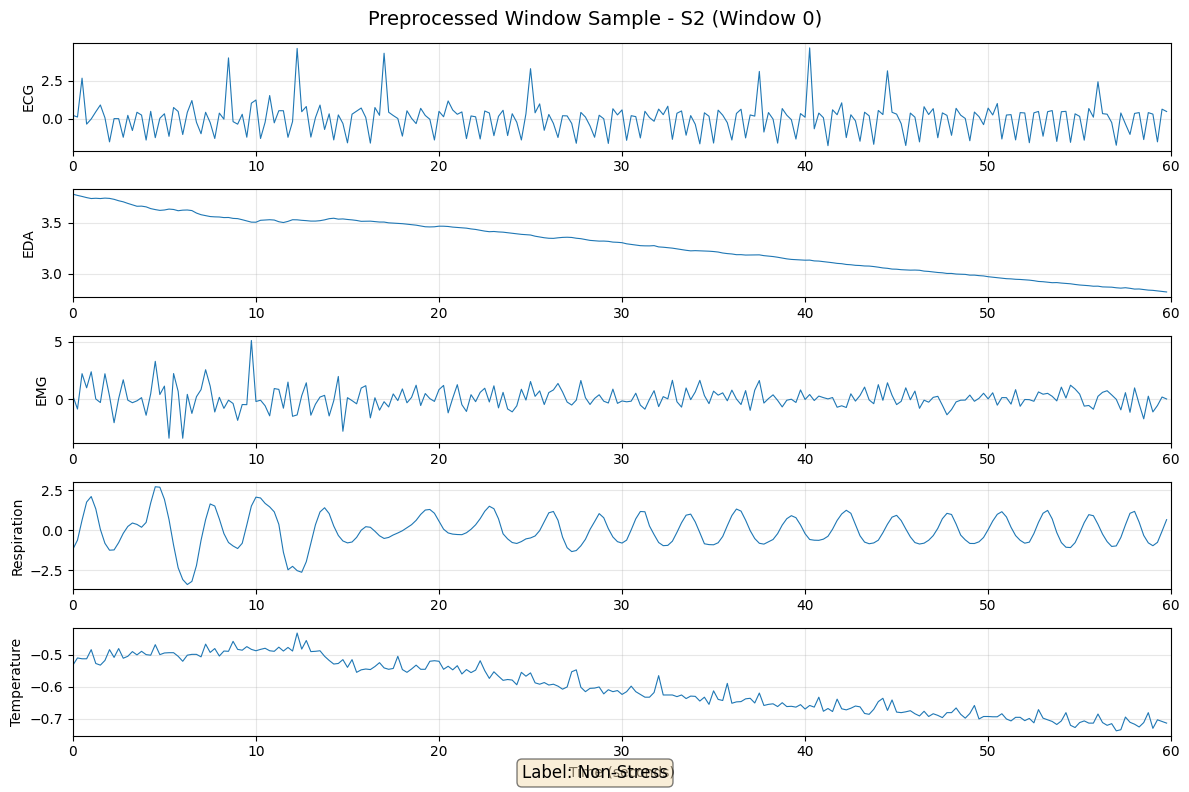


[5/5] Saving preprocessed data...

Preprocessed data saved to: processed_data\preprocessed_windowed_data.pkl

✓ Notebook 2 Complete - Proceed to Notebook 3 (Model)


In [11]:
# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("="*70)
    print("WESAD BINARY STRESS DETECTION - NOTEBOOK 2: PREPROCESSING")
    print("="*70)
    
    # Step 1: Load raw data from Notebook 1
    print("\n[1/4] Loading raw data from Notebook 1...")
    all_data, data_config = load_raw_data()
    
    # Step 2: Preprocess all subjects
    print("\n[2/4] Preprocessing all subjects...")
    print(f"Target sampling rate: {PREPROCESS_CONFIG['target_sampling_rate']} Hz (FIXED)")
    print(f"Window length: {PREPROCESS_CONFIG['window_length_seconds']}s = {PREPROCESS_CONFIG['samples_per_window']} samples (FIXED)")
    print(f"Window overlap: {PREPROCESS_CONFIG['window_overlap']*100:.0f}% (FIXED)")
    print()
    
    preprocessed_data = preprocess_all_subjects(all_data)
    
    # Step 3: Inspect preprocessed data
    print("\n[3/4] Inspecting preprocessed data...")
    inspect_preprocessed_data(preprocessed_data)
    
    # Step 4: Visualize sample
    print("\n[4/4] Visualizing preprocessed window...")
    visualize_preprocessed_window(preprocessed_data)
    
    # Step 5: Save preprocessed data
    print("\n[5/5] Saving preprocessed data...")
    save_preprocessed_data(preprocessed_data)
    
    print("\n" + "="*70)
    print("✓ Notebook 2 Complete - Proceed to Notebook 3 (Model)")
    print("="*70)